<a href="https://colab.research.google.com/github/Zafeerxyz/Machine-Learning-algorithms/blob/main/TreeAndTreesDay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print(X.shape)
print(X.head())
print(y.value_counts())
print(X.isnull().sum().sum())

(569, 30)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0 

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

imputer = SimpleImputer(strategy="median")
X_clean = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)
encoder = OneHotEncoder(handle_unknown="ignore")

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)

y_pred = decision_tree_model.predict(X_test)

from sklearn.metrics import accuracy_score, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.9122807017543859
Confusion Matrix:
 [[39  3]
 [ 7 65]]


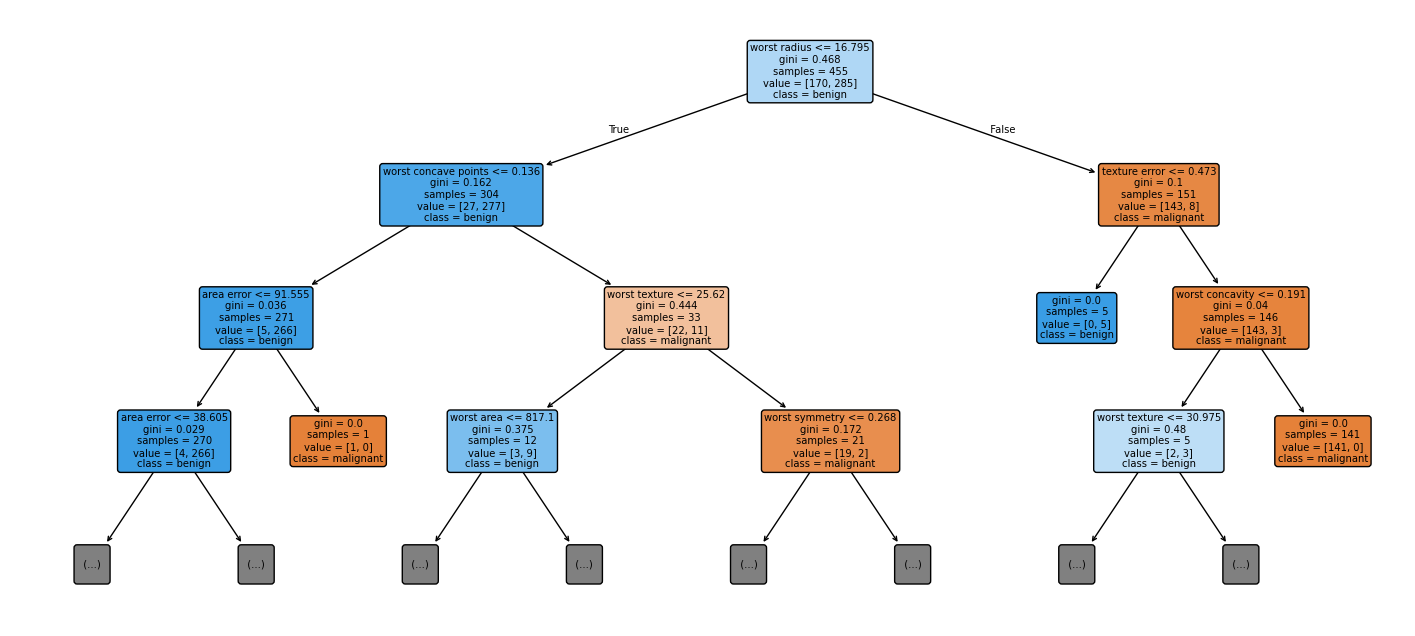

In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))

plot_tree(
    decision_tree_model,
    feature_names=X_train.columns,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    max_depth=3
)

plt.show()

In [13]:
from sklearn.metrics import accuracy_score

results = []

for depth in [1, 2, 3, 5, 10, None]:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, tree.predict(X_train)
    )
    test_acc = accuracy_score(
        y_test, tree.predict(X_test)
    )

    results.append({
        "max_depth": depth,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

results_df = pd.DataFrame(results)
print(results_df)

   max_depth  train_accuracy  test_accuracy
0        1.0        0.923077       0.921053
1        2.0        0.958242       0.894737
2        3.0        0.975824       0.938596
3        5.0        0.993407       0.921053
4       10.0        1.000000       0.912281
5        NaN        1.000000       0.912281


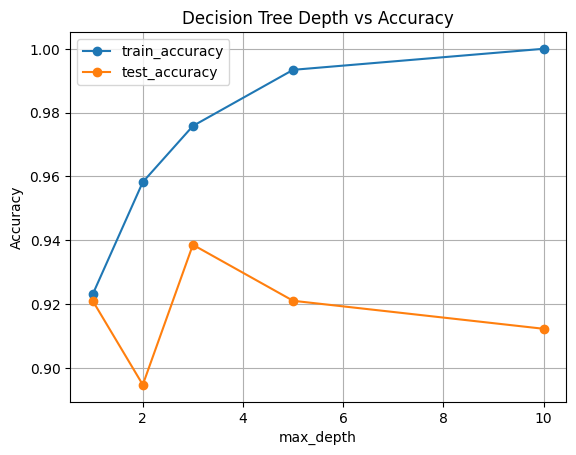

In [14]:
results_df.set_index("max_depth")[
    ["train_accuracy", "test_accuracy"]
].plot(marker="o")

plt.ylabel("Accuracy")
plt.title("Decision Tree Depth vs Accuracy")
plt.grid(True)
plt.show()

In [15]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("OOB accuracy:", model.oob_score_)

OOB accuracy: 0.9538461538461539


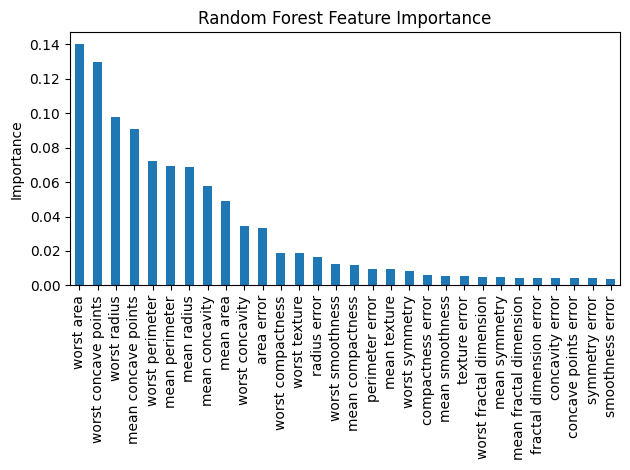

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

importance.plot(kind="bar")
plt.title("Random Forest Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import accuracy_score, confusion_matrix

models = {
    "Decision Tree": decision_tree_model,
    "Random Forest": model
}

for name, estimator in models.items():
    predictions = estimator.predict(X_test)

    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Confusion matrix:\n", confusion_matrix(y_test, predictions))




Decision Tree
Accuracy: 0.9122807017543859
Confusion matrix:
 [[39  3]
 [ 7 65]]

Random Forest
Accuracy: 0.956140350877193
Confusion matrix:
 [[39  3]
 [ 2 70]]
